# 🗽 MTA Ridership: Cleaning, Feature Engineering, Visuals & 180-Day Forecast

This notebook processes the **MTA Raw Data Suite** (four CSV files in one zip archive) and forecasts daily ridership for the next **180 days** using **Prophet**, a time series model from Meta.

**Pipeline**

1. **Setup:** imports and settings in one place
2. **Import:** extract the zip and load the four tables
3. **Inspection:** nulls, duplicates, categories, date ranges, value sanity checks
4. **Cleaning:** fix dates, remove duplicates, label structural nulls, flag suspicious values
5. **Feature engineering:** build a daily table per agency with calendar, lag, and rolling features
6. **Visuals:** trends, seasonality, station map, incidents
7. **Forecasting:** Prophet backtest against a simple baseline, then a 180-day forecast
8. **Documentation & export:** summary table, output files, limitations

**Input files** (place the zip in the same folder as this notebook)
* `raw_mta_detailed_ridership.csv`: one row per date, agency, station, time shift and payment type
* `raw_mta_financials_ops.csv`: one row per date, agency and time shift (trips, revenue, cost, delays)
* `raw_mta_service_incidents.csv`: one row per service incident
* `raw_nyc_stations.csv`: subway station coordinates and attributes

## Section 0: Setup

In [ ]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prophet import Prophet

import logging
import warnings
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)   # hide Prophet's chatter

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [ ]:
# All settings live here so they're easy to change
ZIP_PATH = Path("MTA_Raw_Data_Suite_500K.zip")   # the uploaded archive
EXTRACT_DIR = Path("raw_data")                   # where the CSVs are unpacked
OUTPUT_DIR = Path("outputs")                     # where results are saved
OUTPUT_DIR.mkdir(exist_ok=True)

FORECAST_DAYS = 180          # forecast horizon (was 30)
TRAIN_START = "2021-01-01"   # skip the 2020 lockdown collapse so it doesn't distort the trend

# Column name used for each agency in the daily table
TARGET_NAMES = {
    "Subways": "Subways_Ridership",
    "Buses": "Buses_Ridership",
    "LIRR": "LIRR_Ridership",
    "Metro-North": "MetroNorth_Ridership",
    "Access-A-Ride": "AccessARide_Ridership",
    "Bridges and Tunnels": "Bridges_Tunnels_Ridership",
    "Staten Island Railway": "StatenIsland_Ridership",
}
TARGETS = list(TARGET_NAMES.values())   # the 7 series we forecast
print("Forecast horizon:", FORECAST_DAYS, "days")
print("Series to forecast:", len(TARGETS))

Forecast horizon: 180 days
Series to forecast: 7


## Section 1: Import

The raw data arrives as a zip archive. We extract it into a folder, list what's inside, and then load each CSV.

In [ ]:
EXTRACT_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH) as archive:
    archive.extractall(EXTRACT_DIR)
    print("Files in archive:")
    for info in archive.infolist():
        print(f"  {info.filename:<40} {info.file_size / 1e6:>8.1f} MB")

Files in archive:
  raw_mta_detailed_ridership.csv               30.0 MB
  raw_mta_financials_ops.csv                    3.3 MB
  raw_mta_service_incidents.csv                 1.4 MB
  raw_nyc_stations.csv                          0.0 MB


In [ ]:
ridership_raw = pd.read_csv(EXTRACT_DIR / "raw_mta_detailed_ridership.csv")
financials_raw = pd.read_csv(EXTRACT_DIR / "raw_mta_financials_ops.csv")
incidents_raw = pd.read_csv(EXTRACT_DIR / "raw_mta_service_incidents.csv")
stations_raw = pd.read_csv(EXTRACT_DIR / "raw_nyc_stations.csv")

# Keep the raw tables in one dictionary so the checks below can loop over them
tables = {
    "ridership": ridership_raw,
    "financials": financials_raw,
    "incidents": incidents_raw,
    "stations": stations_raw,
}
for name, table in tables.items():
    print(f"{name:<12} rows: {len(table):>9,}   columns: {table.shape[1]}")

ridership    rows:   450,384   columns: 8
financials   rows:    47,768   columns: 9
incidents    rows:    18,500   columns: 8
stations     rows:        30   columns: 6


In [ ]:
ridership_raw.head()

,Date,Agency,Station_Complex,Borough,Time_Shift,Payment_Type,Estimated_Ridership,Pct_Pre_Pandemic
0,2020-03-01,Subways,Times Sq-42 St,Manhattan,AM Rush,OMNY,2699,97
1,2020-03-01,Subways,Times Sq-42 St,Manhattan,AM Rush,MetroCard,24565,97
2,2020-03-01,Subways,Times Sq-42 St,Manhattan,Midday,OMNY,8071,97
3,2020-03-01,Subways,Times Sq-42 St,Manhattan,Midday,MetroCard,69825,97
4,2020-03-01,Subways,Times Sq-42 St,Manhattan,PM Rush,OMNY,5554,97


## Section 2: Data Inspection

Before changing anything, we check each table for:
* **Data types:** are dates stored as dates and numbers as numbers?
* **Nulls:** which columns have missing values, and how many?
* **Duplicates:** exact duplicate rows, and duplicate keys that should be unique
* **Categories:** the unique values in label columns, to catch typos or unexpected entries
* **Date ranges:** whether every table covers the same period

In [ ]:
for name, table in tables.items():
    print(f"\n=== {name} {table.shape}")
    print(table.dtypes.to_string())


=== ridership (450384, 8)
Date                   object
Agency                 object
Station_Complex        object
Borough                object
Time_Shift             object
Payment_Type           object
Estimated_Ridership     int64
Pct_Pre_Pandemic        int64

=== financials (47768, 9)
Date                        object
Agency                      object
Time_Shift                  object
Scheduled_Trips              int64
Total_Seat_Capacity          int64
Gross_Fare_Revenue_USD     float64
Operating_Expense_USD      float64
Total_Delay_Minutes          int64
On_Time_Performance_Pct    float64

=== incidents (18500, 8)
Incident_ID                   object
Date                          object
Agency                        object
Station_Complex               object
Time_Shift                    object
Incident_Category             object
Delay_Impact_Minutes           int64
Estimated_Repair_Cost_USD    float64

=== stations (30, 6)
Station_Complex     object
Borough             

In [ ]:
for name, table in tables.items():
    nulls = table.isna().sum()
    nulls = nulls[nulls > 0]
    if nulls.empty:
        print(f"{name:<12}: no nulls")
    else:
        print(f"{name:<12}: nulls found")
        print(nulls.to_string(), "\n")

ridership   : nulls found
Station_Complex    40944
Borough            34120 

financials  : no nulls
incidents   : nulls found
Station_Complex    9890 

stations    : no nulls


In [ ]:
# Exact duplicates: every column identical
for name, table in tables.items():
    print(f"{name:<12}: {table.duplicated().sum():>5} exact duplicate rows")

print()
# Key duplicates: rows that should be unique on their key columns
print("Ridership  (Date+Agency+Station+Shift+Payment):",
      ridership_raw.duplicated(subset=["Date", "Agency", "Station_Complex", "Time_Shift", "Payment_Type"]).sum())
print("Financials (Date+Agency+Shift):              ",
      financials_raw.duplicated(subset=["Date", "Agency", "Time_Shift"]).sum())
print("Incidents  (Incident_ID):                    ",
      incidents_raw["Incident_ID"].duplicated().sum())

ridership   :     0 exact duplicate rows
financials  :     0 exact duplicate rows
incidents   :     0 exact duplicate rows
stations    :     0 exact duplicate rows

Ridership  (Date+Agency+Station+Shift+Payment): 0
Financials (Date+Agency+Shift):               0
Incidents  (Incident_ID):                     0


In [ ]:
print("Agencies in ridership:")
print(ridership_raw["Agency"].value_counts().to_string())

print("\nTime shifts:", sorted(ridership_raw["Time_Shift"].unique()))
print("Payment types:", sorted(ridership_raw["Payment_Type"].unique()))
print("\nIncident categories:")
print(incidents_raw["Incident_Category"].value_counts().to_string())

Agencies in ridership:
Agency
Subways                  409440
Buses                      6824
LIRR                       6824
Metro-North                6824
Access-A-Ride              6824
Bridges and Tunnels        6824
Staten Island Railway      6824

Time shifts: ['AM Rush', 'Midday', 'Night', 'PM Rush']
Payment types: ['E-ZPass', 'MetroCard', 'OMNY']

Incident categories:
Incident_Category
Signal Failure          4387
Mechanical Breakdown    4157
Track Maintenance       3350
Crew Shortage           2621
Traffic Congestion      2149
Police/Medical          1836


In [ ]:
# Date ranges: every table should cover the same period with no unparseable dates
for name in ["ridership", "financials", "incidents"]:
    dates = pd.to_datetime(tables[name]["Date"], errors="coerce")
    print(f"{name:<12} {dates.min().date()} to {dates.max().date()}   "
          f"unique days: {dates.nunique():,}   unparseable: {dates.isna().sum()}")

ridership    2020-03-01 to 2024-10-31   unique days: 1,706   unparseable: 0
financials   2020-03-01 to 2024-10-31   unique days: 1,706   unparseable: 0
incidents    2020-03-01 to 2024-10-31   unique days: 1,706   unparseable: 0


In [ ]:
# Value sanity checks. These only FLAG suspicious values; cleaning decides what to do with them.
checks = pd.Series({
    "Ridership: negative values": (ridership_raw["Estimated_Ridership"] < 0).sum(),
    "Ridership: zero values": (ridership_raw["Estimated_Ridership"] == 0).sum(),
    "Pct_Pre_Pandemic above 100": (ridership_raw["Pct_Pre_Pandemic"] > 100).sum(),
    "Financials: zero fare revenue": (financials_raw["Gross_Fare_Revenue_USD"] == 0).sum(),
    "Financials: on-time above 100%": (financials_raw["On_Time_Performance_Pct"] > 100).sum(),
})
print(checks.to_string())

print("\nZero fare revenue rows by agency:")
print(financials_raw.loc[financials_raw["Gross_Fare_Revenue_USD"] == 0, "Agency"].value_counts().to_string())
print("\nZero ridership rows by agency:")
print(ridership_raw.loc[ridership_raw["Estimated_Ridership"] == 0, "Agency"].value_counts().to_string())

Ridership: negative values           0
Ridership: zero values             134
Pct_Pre_Pandemic above 100        6868
Financials: zero fare revenue      128
Financials: on-time above 100%       0

Zero fare revenue rows by agency:
Agency
Staten Island Railway    128

Zero ridership rows by agency:
Agency
Staten Island Railway    134


### Inspection findings and cleaning decisions

| Finding | Decision |
| :--- | :--- |
| `Station_Complex` and `Borough` are null for non-subway agencies | **Structural, not an error.** Only subways have station-level data. Label these rows `Not Applicable`. |
| `Staten Island Railway` has zero-ridership rows | Keep. Likely real low-service days. Flag them. |
| `Pct_Pre_Pandemic` above 100 | Keep. Several agencies (e.g. Bridges and Tunnels) recovered above 2019 levels. |
| Zero fare revenue in some rows | Keep and flag. Revenue is for context only and is not forecast. |
| No exact or key duplicates expected | Code still removes exact duplicates to protect against future data. |

## Section 3: Data Cleaning

In [ ]:
def basic_clean(df, date_col="Date"):
    """Three steps shared by every table:
    1. remove exact duplicate rows
    2. convert the date column to real dates
    3. sort by date and reset the row index"""
    out = df.drop_duplicates().copy()
    out[date_col] = pd.to_datetime(out[date_col])
    return out.sort_values(date_col).reset_index(drop=True)

ridership = basic_clean(ridership_raw)
financials = basic_clean(financials_raw)
incidents = basic_clean(incidents_raw)
stations = stations_raw.drop_duplicates().copy()

In [ ]:
# Structural nulls: non-subway rows have no station, so label them instead of leaving blanks
ridership["Station_Complex"] = ridership["Station_Complex"].fillna("Not Applicable")
ridership["Borough"] = ridership["Borough"].fillna("Not Applicable")
incidents["Station_Complex"] = incidents["Station_Complex"].fillna("Not Applicable")

# Flags: kept in the data so they can be filtered later, not removed
ridership["Is_Zero_Ridership"] = (ridership["Estimated_Ridership"] == 0).astype(int)
ridership["Above_Pre_Pandemic"] = (ridership["Pct_Pre_Pandemic"] > 100).astype(int)
financials["Is_Zero_Fare_Revenue"] = (financials["Gross_Fare_Revenue_USD"] == 0).astype(int)

In [ ]:
# Before/after check for every table
summary_rows = []
for name, before, after in [
    ("ridership", ridership_raw, ridership),
    ("financials", financials_raw, financials),
    ("incidents", incidents_raw, incidents),
    ("stations", stations_raw, stations),
]:
    summary_rows.append({
        "table": name,
        "rows_before": len(before),
        "rows_after": len(after),
        "nulls_after": int(after.isna().sum().sum()),
    })
cleaning_summary = pd.DataFrame(summary_rows)
cleaning_summary

,table,rows_before,rows_after,nulls_after
0,ridership,450384,450384,0
1,financials,47768,47768,0
2,incidents,18500,18500,0
3,stations,30,30,0


In [ ]:
# Export the cleaned tables so they can be loaded into SQL Server or Power BI
OUTPUT_DIR.mkdir(exist_ok=True)
cleaned_tables = {
    "MTA_Ridership_Cleaned.csv": ridership,
    "MTA_Financials_Cleaned.csv": financials,
    "MTA_Incidents_Cleaned.csv": incidents,
    "MTA_Stations_Cleaned.csv": stations,
}
for file_name, table in cleaned_tables.items():
    table.to_csv(OUTPUT_DIR / file_name, index=False)
    print(f"Exported {file_name:<30} {len(table):>9,} rows")

Exported MTA_Ridership_Cleaned.csv        450,384 rows
Exported MTA_Financials_Cleaned.csv        47,768 rows
Exported MTA_Incidents_Cleaned.csv         18,500 rows
Exported MTA_Stations_Cleaned.csv              30 rows


## Section 4: Feature Engineering

We turn the cleaned records into one **daily row per date**, with one column per agency, plus features describing the day.

* **Ridership** is summed across stations, shifts and payment types to get each agency's daily total.
* **Operations** (trips, revenue, cost, delays) and **incidents** are summarised per day as context features.
* **Calendar features** capture weekly and yearly patterns.
* **Lag and rolling features** capture recent history. The rolling average is shifted by one day so today's value never leaks into its own feature.

In [ ]:
# Daily ridership per agency: sum across stations, shifts and payment types
daily_ridership = (
    ridership.groupby(["Date", "Agency"])["Estimated_Ridership"]
    .sum()
    .unstack("Agency")
    .rename(columns=TARGET_NAMES)
)
daily_ridership = daily_ridership[TARGETS]
print("Daily ridership shape:", daily_ridership.shape)
daily_ridership.head()

Daily ridership shape: (1706, 7)


Agency,Subways_Ridership,Buses_Ridership,LIRR_Ridership,MetroNorth_Ridership,AccessARide_Ridership,Bridges_Tunnels_Ridership,StatenIsland_Ridership
Date,,,,,,,
2020-03-01,2212964,954398,85300,57123,19658,775305,1593
2020-03-02,5329914,2193637,320655,183034,30226,874239,17083
2020-03-03,5481105,2212591,321739,191164,32529,881596,16945
2020-03-04,5498807,2215830,312982,191456,34414,897490,16862
2020-03-05,5496450,2251751,313783,194384,33188,916786,16743


In [ ]:
# Daily operations totals across all agencies (context features)
daily_ops = financials.groupby("Date").agg(
    Total_Scheduled_Trips=("Scheduled_Trips", "sum"),
    Total_Fare_Revenue_USD=("Gross_Fare_Revenue_USD", "sum"),
    Total_Operating_Expense_USD=("Operating_Expense_USD", "sum"),
    Total_Delay_Minutes=("Total_Delay_Minutes", "sum"),
)

# Daily incident counts and delay impact
daily_incidents = incidents.groupby("Date").agg(
    Incident_Count=("Incident_ID", "count"),
    Incident_Delay_Minutes=("Delay_Impact_Minutes", "sum"),
)

# Join everything on the date index; days without incidents get 0
daily = daily_ridership.join(daily_ops).join(daily_incidents)
daily["Incident_Count"] = daily["Incident_Count"].fillna(0)
daily["Incident_Delay_Minutes"] = daily["Incident_Delay_Minutes"].fillna(0)

# Make sure there is one row for every calendar day (no gaps)
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
print("Missing days before reindex:", len(full_range) - len(daily))
daily = daily.reindex(full_range)
daily.index.name = "Date"

Missing days before reindex: 0


In [ ]:
# Total ridership across all seven agencies
daily["Total_Ridership"] = daily[TARGETS].sum(axis=1)

# Calendar features
daily["Year"] = daily.index.year
daily["Month"] = daily.index.month
daily["Quarter"] = daily.index.quarter
daily["Day_Name"] = daily.index.day_name()
daily["IsWeekend"] = (daily.index.dayofweek >= 5).astype(int)

print("Calendar features added")
daily[["Year", "Month", "Quarter", "Day_Name", "IsWeekend"]].head()

Calendar features added


,Year,Month,Quarter,Day_Name,IsWeekend
Date,,,,,
2020-03-01,2020,3,1,Sunday,1
2020-03-02,2020,3,1,Monday,0
2020-03-03,2020,3,1,Tuesday,0
2020-03-04,2020,3,1,Wednesday,0
2020-03-05,2020,3,1,Thursday,0


In [ ]:
# Lag and rolling features for every series
for col in TARGETS + ["Total_Ridership"]:
    daily[f"{col}_Lag7"] = daily[col].shift(7)                      # value one week ago
    daily[f"{col}_Roll7_Mean"] = daily[col].shift(1).rolling(7).mean()  # average of the previous 7 days

print("Feature table shape:", daily.shape)
daily.head(10)

Feature table shape: (1706, 35)


,Subways_Ridership,Buses_Ridership,LIRR_Ridership,MetroNorth_Ridership,AccessARide_Ridership,Bridges_Tunnels_Ridership,StatenIsland_Ridership,Total_Scheduled_Trips,Total_Fare_Revenue_USD,Total_Operating_Expense_USD,Total_Delay_Minutes,Incident_Count,Incident_Delay_Minutes,Total_Ridership,Year,Month,Quarter,Day_Name,IsWeekend,Subways_Ridership_Lag7,Subways_Ridership_Roll7_Mean,Buses_Ridership_Lag7,Buses_Ridership_Roll7_Mean,LIRR_Ridership_Lag7,LIRR_Ridership_Roll7_Mean,MetroNorth_Ridership_Lag7,MetroNorth_Ridership_Roll7_Mean,AccessARide_Ridership_Lag7,AccessARide_Ridership_Roll7_Mean,Bridges_Tunnels_Ridership_Lag7,Bridges_Tunnels_Ridership_Roll7_Mean,StatenIsland_Ridership_Lag7,StatenIsland_Ridership_Roll7_Mean,Total_Ridership_Lag7,Total_Ridership_Roll7_Mean
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2020-03-01,2212964,954398,85300,57123,19658,775305,1593,739013,"13,065,082.96","30,699,704.99",595,11,609,4106341,2020,3,1,Sunday,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-03-02,5329914,2193637,320655,183034,30226,874239,17083,1046511,"24,980,443.64","35,378,641.92",764,12,628,8948788,2020,3,1,Monday,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-03-03,5481105,2212591,321739,191164,32529,881596,16945,1038051,"25,693,095.34","34,989,575.64",787,17,792,9137669,2020,3,1,Tuesday,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-03-04,5498807,2215830,312982,191456,34414,897490,16862,1027323,"25,594,716.00","35,341,084.84",844,10,460,9167841,2020,3,1,Wednesday,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-03-05,5496450,2251751,313783,194384,33188,916786,16743,1021022,"26,162,310.09","35,342,060.42",802,12,701,9223085,2020,3,1,Thursday,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-03-06,5189443,2074773,290842,202844,31384,956024,15613,1042111,"25,463,468.04","35,399,382.79",801,9,450,8760923,2020,3,1,Friday,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-03-07,2814640,1253467,104516,76335,18354,835253,2433,744358,"15,314,718.20","30,691,733.26",682,8,425,5104998,2020,3,1,Saturday,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-03-08,2120654,949902,79970,60865,19658,772920,1643,743677,"12,705,925.27","30,698,954.70",621,11,506,4005612,2020,3,1,Sunday,1,"2,212,964.00","4,574,760.43","954,398.00","1,879,492.43","85,300.00","249,973.86","57,123.00","156,620.00","19,658.00","28,536.14","775,305.00","876,670.43","1,593.00","12,467.43","4,106,341.00","7,778,520.71"
2020-03-09,4973511,2127828,276560,186041,29515,880900,16068,1037098,"23,562,189.29","35,786,618.49",740,12,460,8490423,2020,3,1,Monday,0,"5,329,914.00","4,561,573.29","2,193,637.00","1,878,850.14","320,655.00","249,212.43","183,034.00","157,154.57","30,226.00","28,536.14","874,239.00","876,329.71","17,083.00","12,474.57","8,948,788.00","7,764,130.86"


## Section 5: Visuals

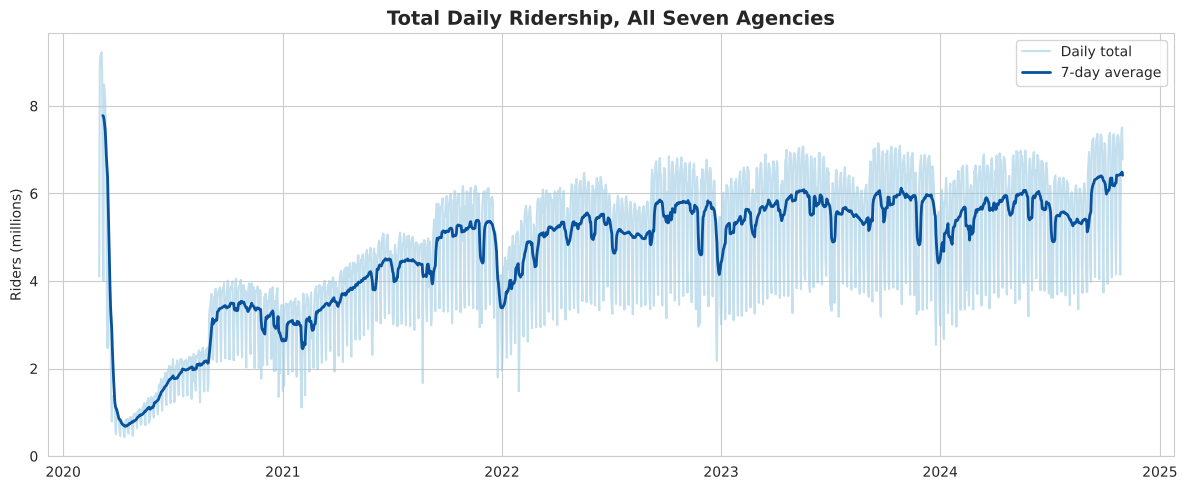

In [ ]:
# Visual 1: total ridership across all agencies
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily.index, daily["Total_Ridership"] / 1e6, color="#9ecae1", alpha=0.6, label="Daily total")
ax.plot(daily.index, daily["Total_Ridership"].rolling(7).mean() / 1e6, color="#08519c", linewidth=2, label="7-day average")
ax.set_title("Total Daily Ridership, All Seven Agencies", fontsize=14, fontweight="bold")
ax.set_ylabel("Riders (millions)")
ax.legend()
plt.tight_layout()
plt.show()

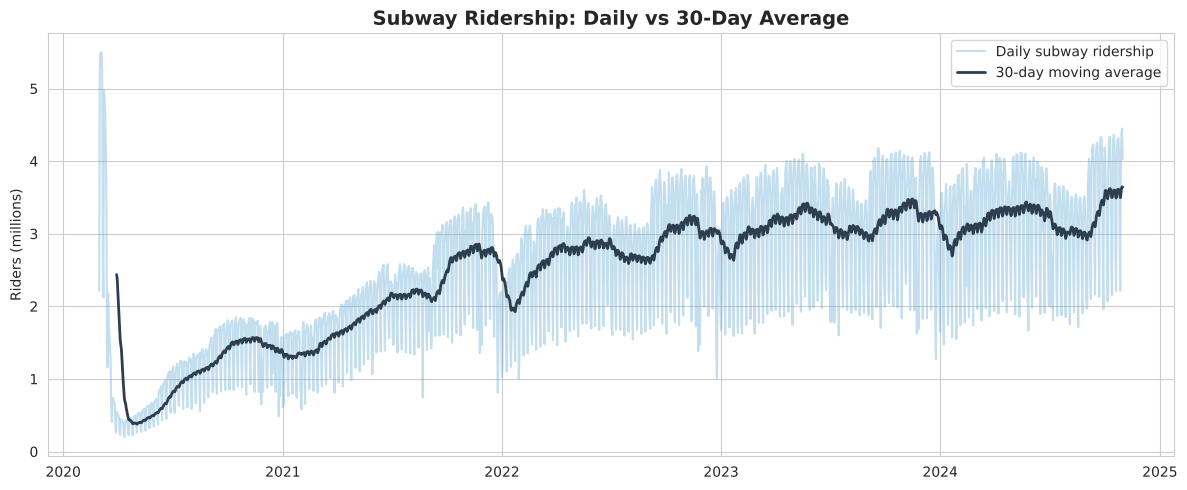

In [ ]:
# Visual 2: subway ridership with a 30-day moving average
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily.index, daily["Subways_Ridership"] / 1e6, color="#6baed6", alpha=0.4, label="Daily subway ridership")
ax.plot(daily.index, daily["Subways_Ridership"].rolling(30).mean() / 1e6, color="#2c3e50", linewidth=2, label="30-day moving average")
ax.set_title("Subway Ridership: Daily vs 30-Day Average", fontsize=14, fontweight="bold")
ax.set_ylabel("Riders (millions)")
ax.legend()
plt.tight_layout()
plt.show()

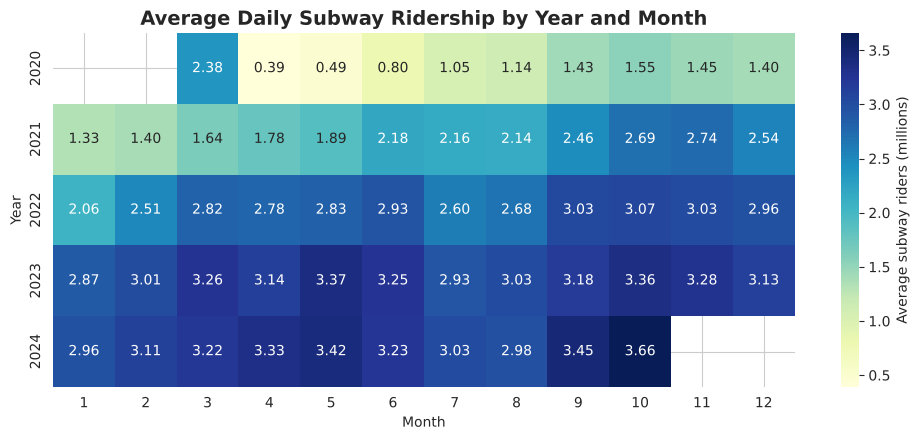

In [ ]:
# Visual 3: average subway ridership by year and month
pivot = daily.pivot_table(values="Subways_Ridership", index="Year", columns="Month", aggfunc="mean") / 1e6

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu",
            cbar_kws={"label": "Average subway riders (millions)"}, ax=ax)
ax.set_title("Average Daily Subway Ridership by Year and Month", fontsize=14, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Year")
plt.tight_layout()
plt.show()

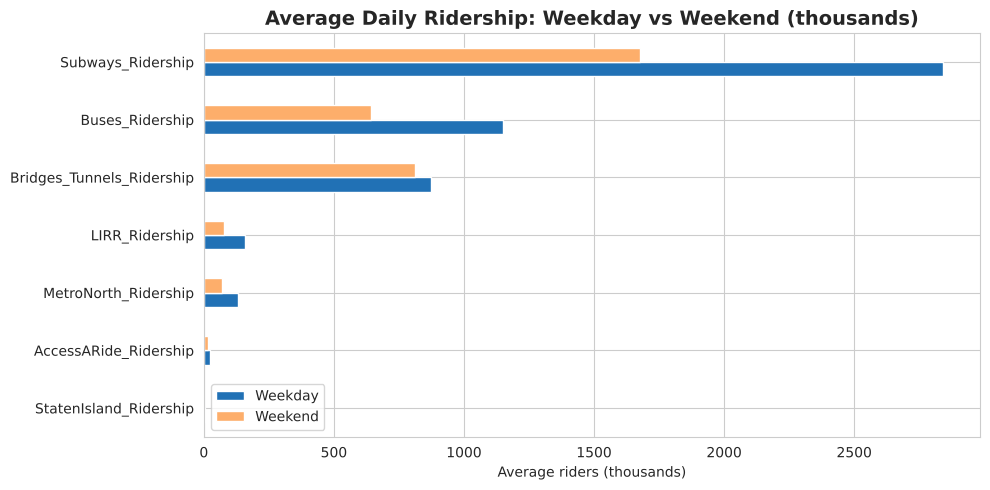

In [ ]:
# Visual 4: weekday vs weekend average per agency, in thousands of riders
wk = daily.groupby("IsWeekend")[TARGETS].mean().T / 1e3
wk.columns = ["Weekday", "Weekend"]

ax = wk.sort_values("Weekday").plot(kind="barh", figsize=(10, 5), color=["#2171b5", "#fdae6b"])
ax.set_title("Average Daily Ridership: Weekday vs Weekend (thousands)", fontsize=14, fontweight="bold")
ax.set_xlabel("Average riders (thousands)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

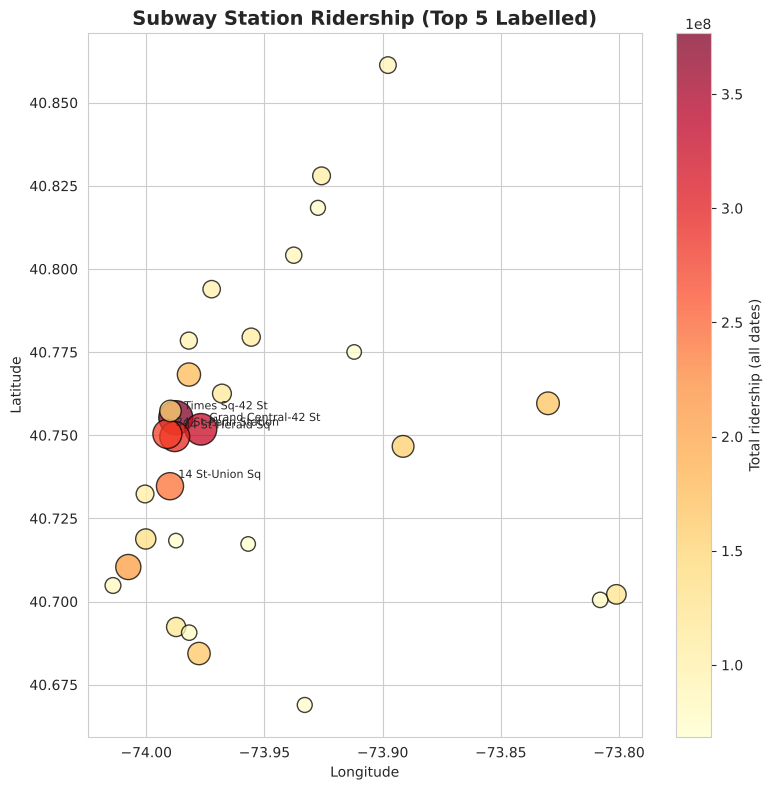

In [ ]:
# Visual 5: subway station map, sized and coloured by total ridership
station_totals = (
    ridership[ridership["Agency"] == "Subways"]
    .groupby("Station_Complex")["Estimated_Ridership"].sum()
    .rename("Total_Ridership")
)
station_map = stations.merge(station_totals, left_on="Station_Complex", right_index=True, how="left")

fig, ax = plt.subplots(figsize=(8, 8))
scatter = ax.scatter(
    station_map["Longitude"], station_map["Latitude"],
    s=station_map["Total_Ridership"] / station_map["Total_Ridership"].max() * 600,
    c=station_map["Total_Ridership"], cmap="YlOrRd", alpha=0.75, edgecolor="black",
)
for _, row in station_map.nlargest(5, "Total_Ridership").iterrows():
    ax.annotate(row["Station_Complex"], (row["Longitude"], row["Latitude"]),
                xytext=(6, 6), textcoords="offset points", fontsize=8)
plt.colorbar(scatter, ax=ax, label="Total ridership (all dates)")
ax.set_title("Subway Station Ridership (Top 5 Labelled)", fontsize=14, fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

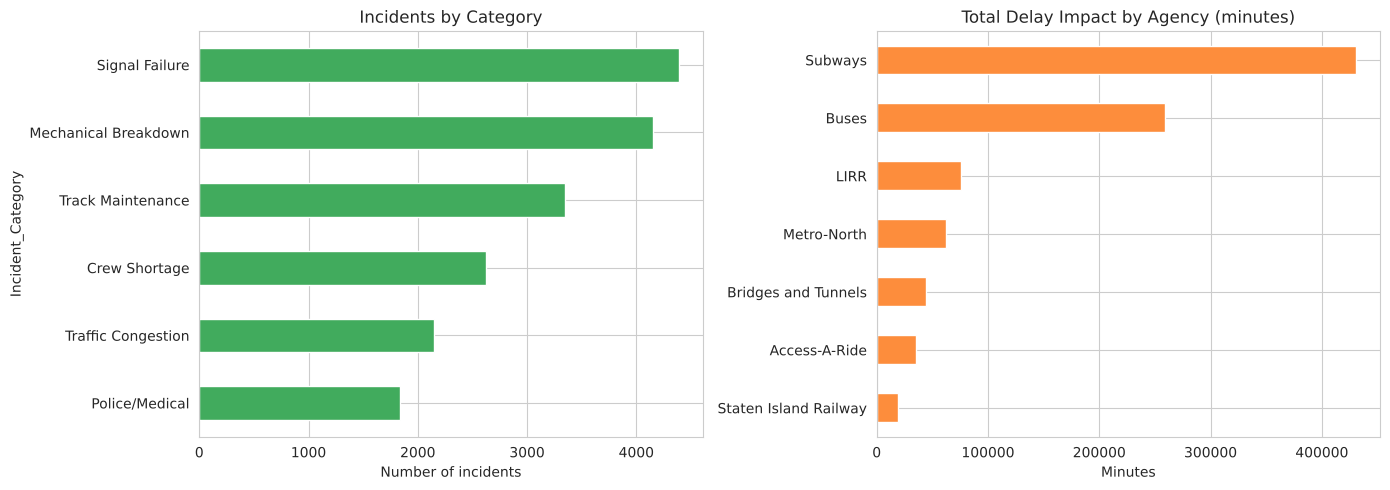

In [ ]:
# Visual 6: incidents by category, and total delay minutes by agency
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

incidents["Incident_Category"].value_counts().sort_values().plot(kind="barh", ax=axes[0], color="#41ab5d")
axes[0].set_title("Incidents by Category")
axes[0].set_xlabel("Number of incidents")

incidents.groupby("Agency")["Delay_Impact_Minutes"].sum().sort_values().plot(kind="barh", ax=axes[1], color="#fd8d3c")
axes[1].set_title("Total Delay Impact by Agency (minutes)")
axes[1].set_xlabel("Minutes")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## Section 6: Forecasting with Prophet

### Why Prophet, and why not Random Forest?

Prophet models a time series as the sum of separate parts:

* **Trend:** the long-term direction, which can bend at changepoints
* **Yearly seasonality:** summer and holiday patterns
* **Weekly seasonality:** weekday vs weekend patterns
* **Holidays:** US public holidays, built in
* **Multiplicative mode:** seasonal swings scale with the level of ridership, which suits transit data

The previous Random Forest model had a structural problem for forecasting. Tree models can only predict values they have seen in training, so a forecast beyond the training period tends to flatten out. Prophet extrapolates its trend, and its components can be inspected and explained.

### How we check the model

1. **Backtest:** hide the last 180 days, train on everything before them, and forecast those 180 days.
2. **Baseline:** compare against a **seasonal naive** forecast, which repeats the last 7 days of training.
3. **Metrics:** MAE (average error in riders) and MAPE (average error as a percentage).
4. **Final model:** retrain on all available data and forecast the next 180 days.

In [ ]:
def fit_prophet(series):
    """Fit a Prophet model to one daily series.
    `series` is a pandas Series with a DatetimeIndex."""
    frame = pd.DataFrame({"ds": series.index, "y": series.values})
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode="multiplicative",
    )
    model.add_country_holidays(country_name="US")
    model.fit(frame)
    return model

def seasonal_naive(train_series, n_days):
    """Baseline: repeat the last 7 days of training data."""
    last_week = train_series.iloc[-7:].values
    repeats = int(np.ceil(n_days / 7))
    return np.tile(last_week, repeats)[:n_days]

print("Prophet helpers ready")

Prophet helpers ready


In [ ]:
# Backtest: hold out the last FORECAST_DAYS days
model_data = daily.loc[TRAIN_START:]
cutoff = model_data.index.max() - pd.Timedelta(days=FORECAST_DAYS)
test_index = model_data.index[model_data.index > cutoff]
print(f"Training data: {model_data.index.min().date()} to {cutoff.date()}")
print(f"Test data:     {test_index.min().date()} to {test_index.max().date()}  ({len(test_index)} days)")

metric_rows = []
for col in TARGETS:
    train_series = model_data.loc[:cutoff, col]
    actual = model_data.loc[test_index, col].values

    model = fit_prophet(train_series)
    future = model.make_future_dataframe(periods=FORECAST_DAYS, freq="D")
    prophet_pred = model.predict(future).set_index("ds").loc[test_index, "yhat"].values
    naive_pred = seasonal_naive(train_series, len(test_index))

    metric_rows.append({
        "Series": col,
        "Prophet_MAE": np.mean(np.abs(actual - prophet_pred)),
        "Prophet_MAPE_%": np.mean(np.abs((actual - prophet_pred) / actual)) * 100,
        "Naive_MAE": np.mean(np.abs(actual - naive_pred)),
        "Naive_MAPE_%": np.mean(np.abs((actual - naive_pred) / actual)) * 100,
    })

backtest_metrics = pd.DataFrame(metric_rows)
backtest_metrics["Prophet_beats_naive"] = backtest_metrics["Prophet_MAE"] < backtest_metrics["Naive_MAE"]
backtest_metrics

Training data: 2021-01-01 to 2024-05-04
Test data:     2024-05-05 to 2024-10-31  (180 days)


10:50:06 - cmdstanpy - INFO - Chain [1] start processing


10:50:06 - cmdstanpy - INFO - Chain [1] done processing


10:50:06 - cmdstanpy - INFO - Chain [1] start processing


10:50:06 - cmdstanpy - INFO - Chain [1] done processing


10:50:06 - cmdstanpy - INFO - Chain [1] start processing


... (6 outputs left out)

10:50:08 - cmdstanpy - INFO - Chain [1] done processing


10:50:08 - cmdstanpy - INFO - Chain [1] start processing


10:50:08 - cmdstanpy - INFO - Chain [1] done processing


,Series,Prophet_MAE,Prophet_MAPE_%,Naive_MAE,Naive_MAPE_%,Prophet_beats_naive
0,Subways_Ridership,"135,648.88",4.39,"294,668.45",9.74,True
1,Buses_Ridership,"93,413.94",8.10,"120,243.16",10.80,True
2,LIRR_Ridership,"9,935.57",5.00,"20,709.28",10.71,True
3,MetroNorth_Ridership,"9,128.95",5.53,"15,300.88",9.55,True
4,AccessARide_Ridership,"1,074.47",3.88,"2,367.32",8.42,True
5,Bridges_Tunnels_Ridership,"30,250.18",3.24,"44,781.48",4.76,True
6,StatenIsland_Ridership,487.47,12.43,705.31,13.91,True


In [ ]:
# Final model: retrain on all data and forecast the next FORECAST_DAYS days
last_date = model_data.index.max()
future_index = pd.date_range(last_date + pd.Timedelta(days=1), periods=FORECAST_DAYS, freq="D")

forecast_parts = []
for col in TARGETS:
    model = fit_prophet(model_data[col])
    future = model.make_future_dataframe(periods=FORECAST_DAYS, freq="D")
    pred = model.predict(future).set_index("ds").loc[future_index, ["yhat", "yhat_lower", "yhat_upper"]]
    pred = pred.clip(lower=0)   # ridership cannot be negative
    pred.columns = [f"{col}_Forecast", f"{col}_Lower", f"{col}_Upper"]
    forecast_parts.append(pred)

forecast = pd.concat(forecast_parts, axis=1)
forecast.index.name = "Date"
print(f"Forecast: {forecast.index.min().date()} to {forecast.index.max().date()}  ({len(forecast)} days)")
forecast.head()

10:50:09 - cmdstanpy - INFO - Chain [1] start processing


10:50:09 - cmdstanpy - INFO - Chain [1] done processing


10:50:09 - cmdstanpy - INFO - Chain [1] start processing


10:50:09 - cmdstanpy - INFO - Chain [1] done processing


10:50:10 - cmdstanpy - INFO - Chain [1] start processing


10:50:10 - cmdstanpy - INFO - Chain [1] done processing


... (6 outputs left out)

10:50:11 - cmdstanpy - INFO - Chain [1] start processing


10:50:12 - cmdstanpy - INFO - Chain [1] done processing


Forecast: 2024-11-01 to 2025-04-29  (180 days)


,Subways_Ridership_Forecast,Subways_Ridership_Lower,Subways_Ridership_Upper,Buses_Ridership_Forecast,Buses_Ridership_Lower,Buses_Ridership_Upper,LIRR_Ridership_Forecast,LIRR_Ridership_Lower,LIRR_Ridership_Upper,MetroNorth_Ridership_Forecast,MetroNorth_Ridership_Lower,MetroNorth_Ridership_Upper,AccessARide_Ridership_Forecast,AccessARide_Ridership_Lower,AccessARide_Ridership_Upper,Bridges_Tunnels_Ridership_Forecast,Bridges_Tunnels_Ridership_Lower,Bridges_Tunnels_Ridership_Upper,StatenIsland_Ridership_Forecast,StatenIsland_Ridership_Lower,StatenIsland_Ridership_Upper
Date,,,,,,,,,,,,,,,,,,,,,
2024-11-01,"4,002,722.92","3,766,450.71","4,243,363.06","1,352,377.11","1,243,761.41","1,471,403.70","252,501.37","239,886.18","266,926.24","217,863.37","204,120.96","230,693.65","37,542.59","35,358.30","39,425.94","993,170.83","928,228.03","1,057,742.80","7,270.02","6,477.69","8,012.65"
2024-11-02,"2,816,680.61","2,577,288.49","3,056,112.72","896,313.00","786,132.77","1,010,777.37","143,179.86","128,451.22","155,829.83","136,716.10","123,685.01","150,450.14","23,574.13","21,567.11","25,626.70","922,137.51","856,149.14","985,481.06","3,057.43","2,205.58","3,833.99"
2024-11-03,"2,299,886.63","2,048,678.55","2,551,751.31","716,451.18","612,516.96","836,118.91","122,611.53","109,275.37","135,904.99","114,092.08","99,760.59","128,540.76","23,207.07","21,188.95","25,194.47","872,238.35","806,275.58","943,005.91","2,582.60","1,806.30","3,383.61"
2024-11-04,"3,828,126.52","3,560,349.03","4,058,823.00","1,344,336.80","1,229,289.59","1,458,988.74","248,516.64","233,607.09","260,994.95","216,792.88","203,181.78","230,122.70","35,825.49","33,813.05","37,946.07","916,406.07","851,772.76","985,664.71","7,720.26","6,898.68","8,502.51"
2024-11-05,"4,127,740.53","3,882,186.36","4,381,882.07","1,386,260.31","1,272,193.67","1,502,622.58","267,490.41","253,531.77","281,694.04","238,955.25","225,794.08","253,878.76","38,518.77","36,547.02","40,773.21","927,523.93","860,084.41","992,472.93","8,393.80","7,641.87","9,167.47"


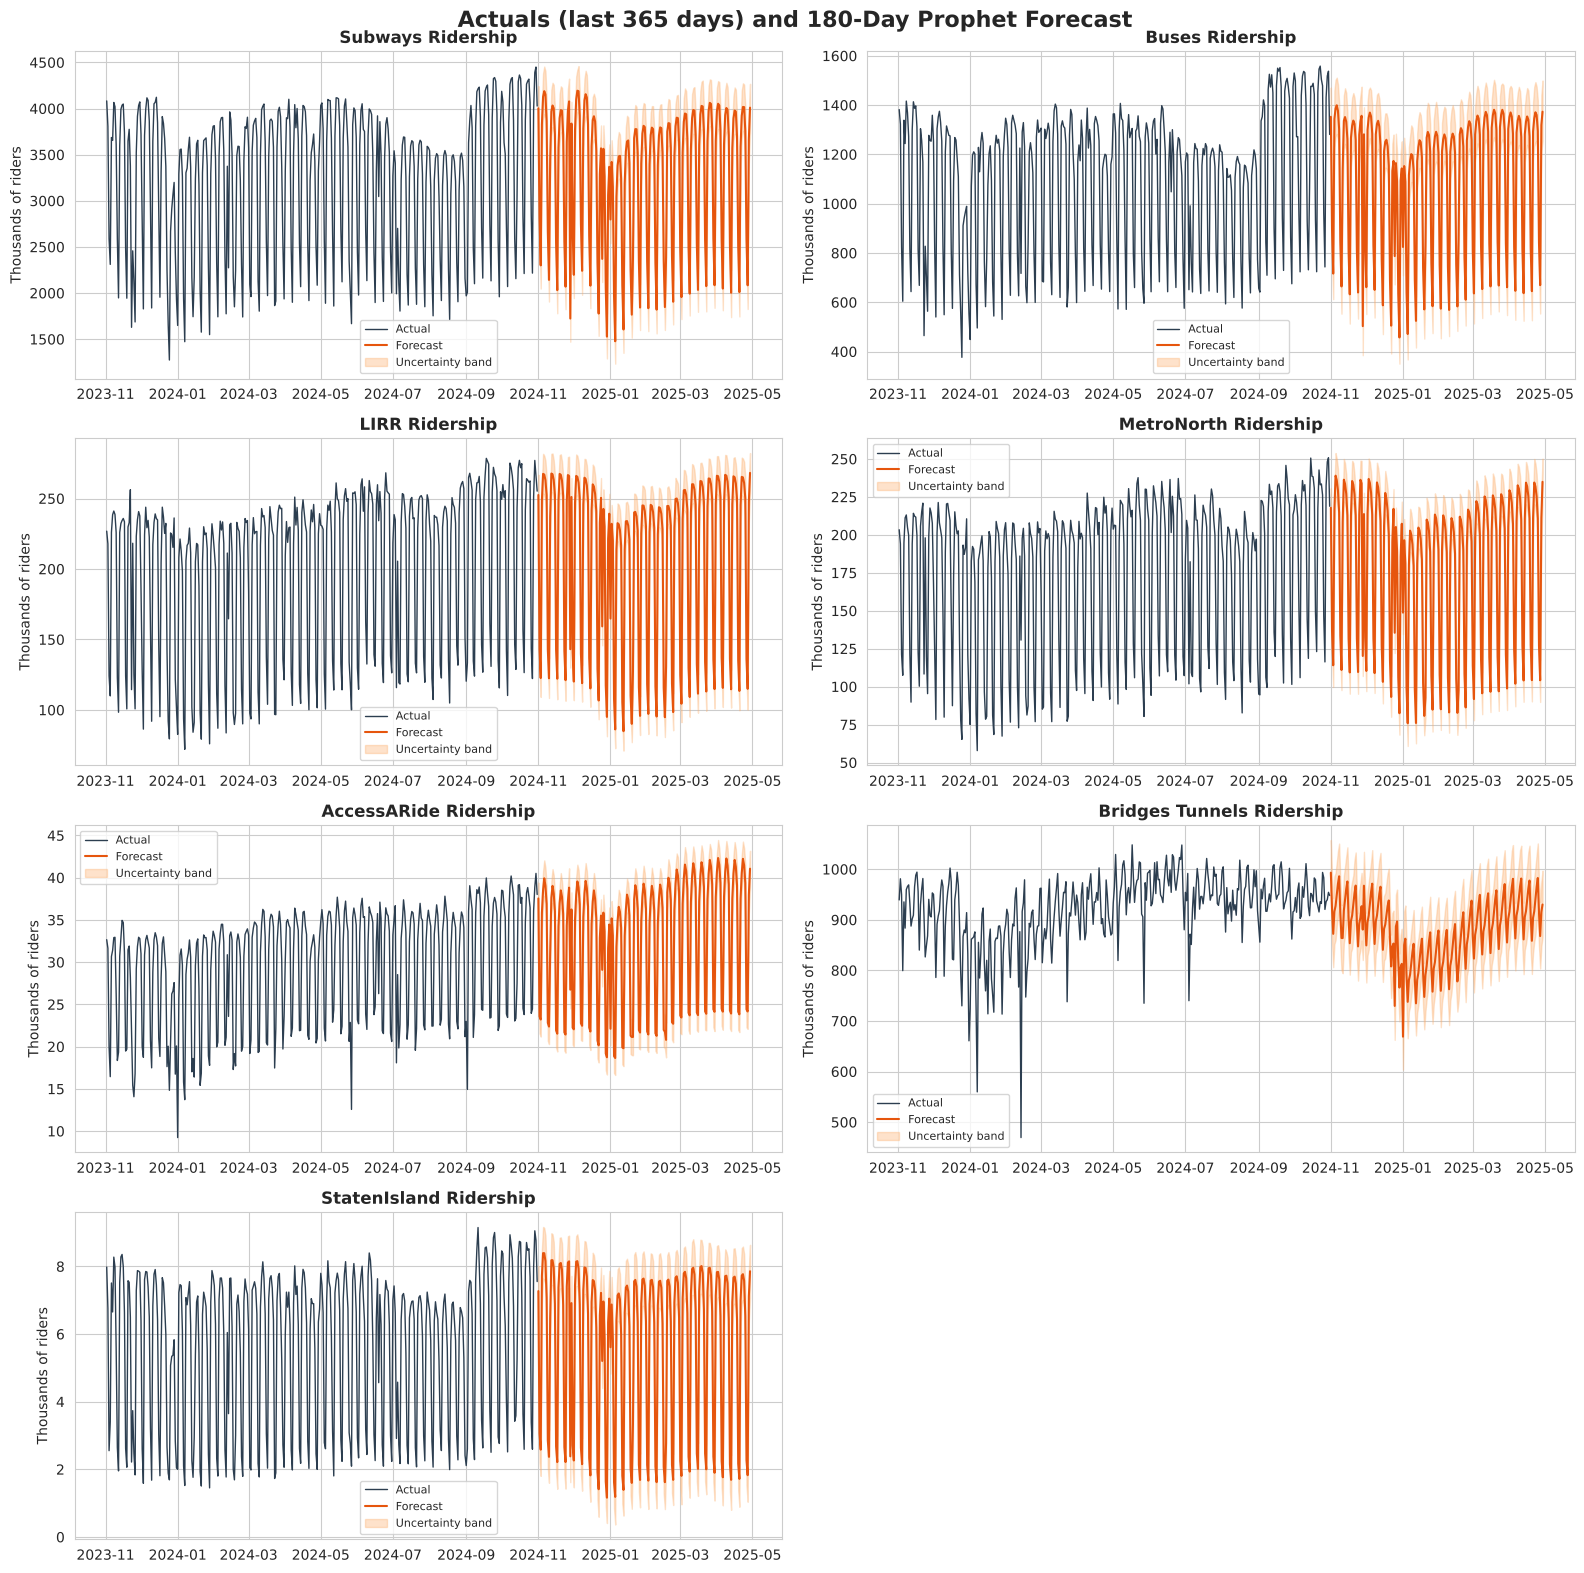

In [ ]:
# Plot the last 365 days of actuals with the 180-day forecast for each series
fig, axes = plt.subplots(4, 2, figsize=(16, 16))
axes = axes.flatten()

history = model_data.loc[last_date - pd.Timedelta(days=364):]
for ax, col in zip(axes, TARGETS):
    ax.plot(history.index, history[col] / 1e3, color="#2c3e50", linewidth=1, label="Actual")
    ax.plot(forecast.index, forecast[f"{col}_Forecast"] / 1e3, color="#e6550d", linewidth=1.5, label="Forecast")
    ax.fill_between(forecast.index,
                    forecast[f"{col}_Lower"] / 1e3,
                    forecast[f"{col}_Upper"] / 1e3,
                    color="#fdae6b", alpha=0.35, label="Uncertainty band")
    ax.set_title(col.replace("_", " "), fontweight="bold")
    ax.set_ylabel("Thousands of riders")
    ax.legend(fontsize=8)

axes[-1].axis("off")   # 8th panel is unused
fig.suptitle(f"Actuals (last 365 days) and {FORECAST_DAYS}-Day Prophet Forecast", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# Forecast summary: weekday vs weekend averages, mirroring the original report
is_weekend = forecast.index.dayofweek >= 5
rows = []
for col in TARGETS:
    series = forecast[f"{col}_Forecast"]
    weekday_avg = series[~is_weekend].mean()
    weekend_avg = series[is_weekend].mean()
    rows.append({
        "Transit Metric": col,
        "Weekday Average": round(weekday_avg),
        "Weekend Average": round(weekend_avg),
        "Weekend vs Weekday (%)": round((weekend_avg / weekday_avg - 1) * 100, 1),
    })

forecast_summary = pd.DataFrame(rows)
forecast_summary

,Transit Metric,Weekday Average,Weekend Average,Weekend vs Weekday (%)
0,Subways_Ridership,3704856,2204680,-40.50
1,Buses_Ridership,1262638,698372,-44.70
2,LIRR_Ridership,244124,118169,-51.60
3,MetroNorth_Ridership,208681,107127,-48.70
4,AccessARide_Ridership,37380,22349,-40.20
5,Bridges_Tunnels_Ridership,894469,842620,-5.80
6,StatenIsland_Ridership,7178,2049,-71.40


## Section 7: Documentation & Export

Every output below is generated by the code above, so the numbers always match the data.
The main datasets are saved to the `outputs` folder.

In [ ]:
# Export the cleaned daily feature table, the backtest metrics, the forecast and the summary
daily.to_csv(OUTPUT_DIR / "MTA_Daily_Features.csv")
backtest_metrics.to_csv(OUTPUT_DIR / "MTA_Backtest_Metrics.csv", index=False)
forecast.to_csv(OUTPUT_DIR / f"MTA_{FORECAST_DAYS}Day_Forecast.csv")
forecast_summary.to_csv(OUTPUT_DIR / "MTA_Forecast_Summary.csv", index=False)

print("Saved to", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f"  {p.name:<35} {p.stat().st_size / 1e6:>6.2f} MB")

Saved to /home/claude/mta/run/outputs
  MTA_180Day_Forecast.csv               0.07 MB
  MTA_Backtest_Metrics.csv              0.00 MB
  MTA_Daily_Features.csv                0.57 MB
  MTA_Financials_Cleaned.csv            3.42 MB
  MTA_Forecast_Summary.csv              0.00 MB
  MTA_Incidents_Cleaned.csv             1.53 MB
  MTA_Ridership_Cleaned.csv            32.87 MB
  MTA_Stations_Cleaned.csv              0.00 MB


In [ ]:
# Run summary: a short text record of this run
n_days = len(daily)
run_summary = f"""MTA Ridership Pipeline: Run Summary
==================================
Source archive:      {ZIP_PATH.name}
Date coverage:       {daily.index.min().date()} to {daily.index.max().date()} ({n_days:,} days)
Ridership rows:      {len(ridership_raw):,} raw -> {len(ridership):,} cleaned
Financial rows:      {len(financials_raw):,} raw -> {len(financials):,} cleaned
Incident rows:       {len(incidents_raw):,} raw -> {len(incidents):,} cleaned
Model:               Prophet (weekly + yearly + US holiday seasonality, multiplicative)
Training start:      {TRAIN_START}
Forecast horizon:    {FORECAST_DAYS} days ({forecast.index.min().date()} to {forecast.index.max().date()})

Backtest (last {FORECAST_DAYS} days held out):
{backtest_metrics.round(2).to_string(index=False)}

Series where Prophet beats the seasonal naive baseline: {int(backtest_metrics['Prophet_beats_naive'].sum())} of {len(TARGETS)}
"""
(OUTPUT_DIR / "MTA_Run_Summary.txt").write_text(run_summary)
print(run_summary)

MTA Ridership Pipeline: Run Summary
Source archive:      MTA_Raw_Data_Suite_500K.zip
Date coverage:       2020-03-01 to 2024-10-31 (1,706 days)
Ridership rows:      450,384 raw -> 450,384 cleaned
Financial rows:      47,768 raw -> 47,768 cleaned
Incident rows:       18,500 raw -> 18,500 cleaned
Model:               Prophet (weekly + yearly + US holiday seasonality, multiplicative)
Training start:      2021-01-01
Forecast horizon:    180 days (2024-11-01 to 2025-04-29)

Backtest (last 180 days held out):
                   Series  Prophet_MAE  Prophet_MAPE_%  Naive_MAE  Naive_MAPE_%  Prophet_beats_naive
        Subways_Ridership   135,648.88            4.39 294,668.45          9.74                 True
          Buses_Ridership    93,413.94            8.10 120,243.16         10.80                 True
           LIRR_Ridership     9,935.57            5.00  20,709.28         10.71                 True
     MetroNorth_Ridership     9,128.95            5.53  15,300.88          9.55        